In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("noisy_curvefit_data.csv")
df

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113
...,...,...,...,...,...,...
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548


In [3]:
df.shape# There are 100 rows and 6 columns

(100, 6)

In [4]:
df.head(5)

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [5]:
df.tail(5)

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [6]:
# There column names are x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, and y_noise_5

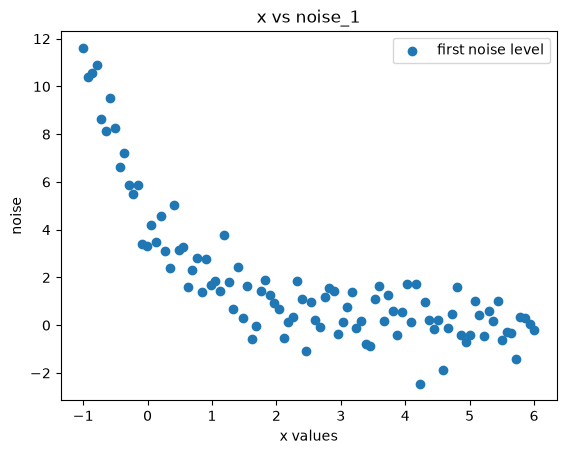

In [7]:
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], label = "first noise level")
plt.title("x vs noise_1")
plt.xlabel("x values")
plt.ylabel("noise")
plt.legend()
plt.show()

In [8]:
def model(x, A, k):
    return A * np.exp(-k * x)
x = df["x"]
y_noise_1 = df["y_noise_1"]

In [10]:
p0 = [1, 1]

In [22]:
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)
A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [12]:
residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof
print(chi2_reduced)

0.7906732087457313


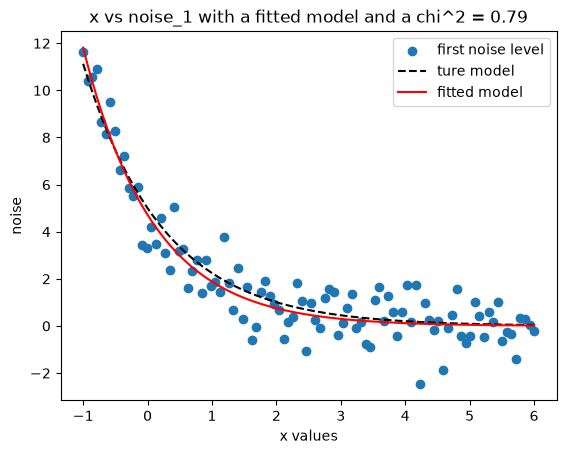

In [13]:
plt.figure()
plt.scatter(df["x"], df["y_noise_1"], label = "first noise level")
plt.plot(x, model(x, 5, 0.8), linestyle = '--', label = "ture model", color = "black")
plt.plot(x, model(x, A_fit, k_fit), color = "red", label = "fitted model")
plt.title("x vs noise_1 with a fitted model and a chi^2 = 0.79")
plt.xlabel("x values")
plt.ylabel("noise")
plt.legend()
plt.show()

In [14]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return(popt, chi2_reduced)

5.06388869738439 0.7303962611566385
5.6093960072277556 0.8703719511733142
5.7387267381529385 0.7259648869040801
4.943458473860519 0.6950119288003864


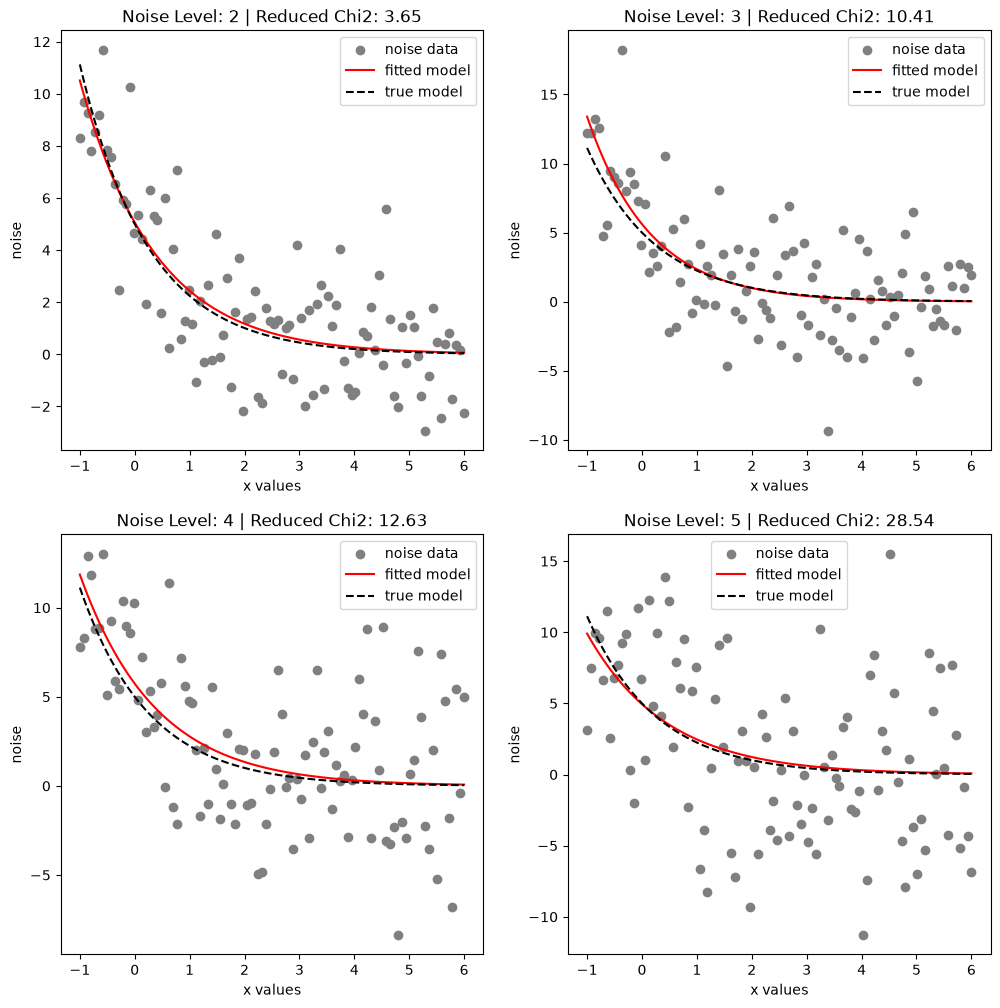

In [18]:
fig, axes = plt.subplots(2, 2, figsize = (12, 12))
noise_columns = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]
for level, (ax, col) in enumerate(zip(axes.flatten(), noise_columns), start=2):
    y_data = df[col]
    popt, chi2_red = fit_model(x, y_data)
    A_fit, k_fit = popt
    ax.scatter(x, y_data, color="gray", label="noise data")
    ax.plot(x, model(x, A_fit, k_fit), color="red", label="fitted model")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="true model")
    ax.set_title(f"Noise Level: {level} | Reduced Chi2: {chi2_red:.2f}")
    ax.set_xlabel("x values")
    ax.set_ylabel("noise")
    ax.legend()
    print(A_fit, k_fit)
plt.show()

In [17]:
# The black line remains the same as it is just the same value for all graphs. The red line shifts ever so slightly between different noise values.
# The chi squared value increases significantly between noise values. They increase a lot because the data points are getting further and further away from the curve

In [24]:
noise_df = pd.DataFrame({"noise_level": [1, 2, 3, 4, 5], "A_fit": [4.71, 5.06, 5.61, 5.74, 4.94], 
                         "k_fit": [0.92, 0.73, 0.87, 0.72, 0.69], "chi2": [0.79, 3.65, 10.41, 12.63, 28.54]
})

In [25]:
print(noise_df)

   noise_level  A_fit  k_fit   chi2
0            1   4.71   0.92   0.79
1            2   5.06   0.73   3.65
2            3   5.61   0.87  10.41
3            4   5.74   0.72  12.63
4            5   4.94   0.69  28.54


In [27]:
noise_df.to_csv("noisy_parameters.csv", index=False)